In [ ]:
!unzip -q archive.zip -d /content/taco/

In [ ]:
import yaml

data_yaml = dict(
    train = '/content/taco/train/images',
    test = '/content/taco/test/images',
    val = '/content/taco/valid/images',
    nc =18,
    names =['Aluminium foil', 'Bottle cap', 'Bottle', 'Broken glass', 'Can',
            'Carton', 'Cigarette', 'Cup', 'Lid', 'Other litter', 'Other plastic',
            'Paper', 'Plastic bag - wrapper', 'Plastic container', 'Pop tab',
            'Straw', 'Styrofoam piece', 'Unlabeled litter']
)

with open('data.yaml', 'w') as outfile:
    yaml.dump(data_yaml, outfile, default_flow_style=True)
    print("Yaml created")

Yaml created


In [1]:
!pip install ultralytics -q

In [2]:
import os
import yaml

import ultralytics
from ultralytics import YOLO
ultralytics.checks()

Ultralytics 8.4.115  Python-3.12.12 torch-2.12.0+cpu CPU (13th Gen Intel Core i5-13450HX)
Setup complete  (16 CPUs, 15.7 GB RAM, 107.7/238.3 GB disk)


In [10]:
yaml_path = "../dataset/data.yaml"

In [11]:
print(os.listdir(os.path.dirname(yaml_path)))

['data.yaml', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [12]:
model = YOLO("yolov8n.pt")

In [13]:
model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="../runs",
    name="finetuning_yolov8_litter"
)

New https://pypi.org/project/ultralytics/8.4.121 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.12.12 torch-2.12.0+cpu 


ValueError: Invalid CUDA 'device=0' requested. Use 'device=cpu' or pass valid CUDA device(s) if available, i.e. 'device=0' or 'device=0,1,2,3' for Multi-GPU.

torch.cuda.is_available(): False
torch.cuda.device_count(): 0
os.environ['CUDA_VISIBLE_DEVICES']: None
See https://pytorch.org/get-started/locally/ for up-to-date torch install instructions if no CUDA devices are seen by torch.


In [ ]:
!zip -r runs.zip runs/

  adding: runs/ (stored 0%)
  adding: runs/finetuning_yolov8_litter/ (stored 0%)
  adding: runs/finetuning_yolov8_litter/val_batch2_pred.jpg (deflated 4%)
  adding: runs/finetuning_yolov8_litter/labels.jpg (deflated 24%)
  adding: runs/finetuning_yolov8_litter/train_batch2.jpg (deflated 1%)
  adding: runs/finetuning_yolov8_litter/train_batch10520.jpg (deflated 4%)
  adding: runs/finetuning_yolov8_litter/val_batch0_labels.jpg (deflated 10%)
  adding: runs/finetuning_yolov8_litter/train_batch0.jpg (deflated 1%)
  adding: runs/finetuning_yolov8_litter/train_batch10522.jpg (deflated 5%)
  adding: runs/finetuning_yolov8_litter/results.csv (deflated 61%)
  adding: runs/finetuning_yolov8_litter/BoxR_curve.png (deflated 5%)
  adding: runs/finetuning_yolov8_litter/confusion_matrix.png (deflated 13%)
  adding: runs/finetuning_yolov8_litter/results.png (deflated 7%)
  adding: runs/finetuning_yolov8_litter/val_batch1_labels.jpg (deflated 4%)
  adding: runs/finetuning_yolov8_litter/weights/ (stored

In [ ]:
metrics = model.val(
    data=yaml_path,
    split="val"
)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,009,158 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1582.1±522.9 MB/s, size: 37.0 KB)
val: Scanning /content/taco/valid/labels.cache... 1704 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1704/1704 446.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 107/107 6.4it/s 16.6s
                   all       1704       4830      0.562      0.349      0.359      0.272
        Aluminium foil         48         62      0.683      0.468      0.466      0.374
            Bottle cap        347        459      0.569      0.649      0.631      0.481
                Bottle        275        320      0.672      0.416      0.466      0.307
          Broken glass         13        123      0.289     0.0732     0.0564     0.0218
                   Can        187        267

In [ ]:
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

mAP50: 0.3588784153352246
mAP50-95: 0.2717892587833623


In [ ]:
test_metrics = model.val(
    data=yaml_path,
    split="test"
)

print("Test mAP50:", test_metrics.box.map50)
print("Test mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 14.6±12.3 MB/s, size: 39.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/taco/test/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.1Kit/s 0.1s
val: New cache created: /content/taco/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4it/s 3.0s
                   all        100        394      0.743       0.57      0.622       0.49
        Aluminium foil          1          6      0.878          1      0.995      0.877
            Bottle cap         24         26      0.879      0.837      0.916      0.693
                Bottle         12         13      0.748      0.385      0.543      0.337
          Broken glas

In [ ]:
import glob

test_images = glob.glob(
    "/content/taco/test/images/*"
)

print("Number of test images:", len(test_images))
print(test_images[:5])

results = model.predict(
    source=test_images[0],
    conf=0.25,
    save=True
)

from IPython.display import Image, display

display(Image(filename=str(results[0].save_dir / test_images[0].split("/")[-1])))


Number of test images: 100
['/content/taco/test/images/000019_jpg.rf.bbee53f6bece0ee564e015c856e196fb.jpg', '/content/taco/test/images/000004_JPG_jpg.rf.3900d00301a00b6e42fdd88edb2bdf23.jpg', '/content/taco/test/images/000028_jpg.rf.38412e9f7a41322ecdac1087d3e69778.jpg', '/content/taco/test/images/000018_jpg.rf.02810d8827408a7e8708da09df3b6b11.jpg', '/content/taco/test/images/000016_jpg.rf.f2d4de09bb4dd8abc77d0d637d1bf959.jpg']

image 1/1 /content/taco/test/images/000019_jpg.rf.bbee53f6bece0ee564e015c856e196fb.jpg: 640x640 1 Bottle cap, 8.6ms
Speed: 4.1ms preprocess, 8.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


TypeError: unsupported operand type(s) for /: 'str' and 'str'


image 1/1 /content/taco/test/images/000019_jpg.rf.bbee53f6bece0ee564e015c856e196fb.jpg: 640x640 1 Bottle cap, 11.9ms
Speed: 4.1ms preprocess, 11.9ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/taco/test/images/000004_JPG_jpg.rf.3900d00301a00b6e42fdd88edb2bdf23.jpg: 640x640 1 Plastic bag - wrapper, 7.3ms
Speed: 2.7ms preprocess, 7.3ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/taco/test/images/000028_jpg.rf.38412e9f7a41322ecdac1087d3e69778.jpg: 640x640 1 Bottle cap, 1 Bottle, 1 Can, 1 Cigarette, 1 Paper, 2 Unlabeled litters, 7.2ms
Speed: 2.7ms preprocess, 7.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/taco/test/images/000018_jpg.rf.02810d8827408a7e8708da09df3b6b11.jpg: 640x640 1 Bottle cap, 1 Cigarette, 7.3ms
Speed: 3.4ms preprocess, 7.3ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/taco/test/images/000016_jpg.rf.f2d4de0

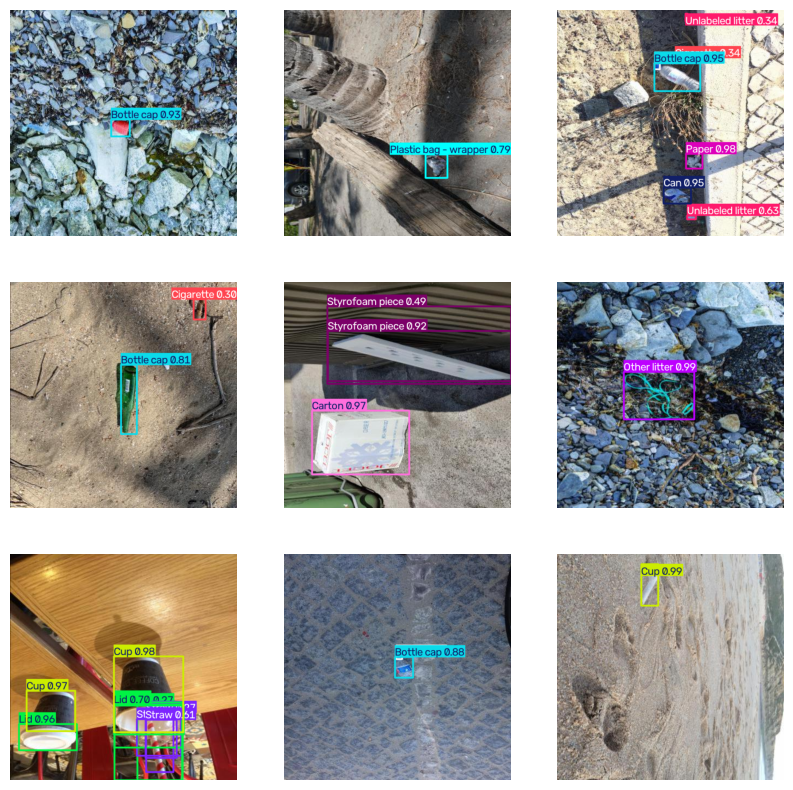

In [ ]:
import matplotlib.pyplot as plt
import cv2
test_dir = '/content/taco/test/images'

plt.figure(figsize = (10,10))
for idx, val in enumerate(os.listdir(test_dir)[0:9]):
    img = os.path.join(test_dir,val)
    result = model(img)
    for r in result:
        img_plot = r.plot()
        img_plot = cv2.cvtColor(img_plot, cv2.COLOR_BGR2RGB)
        plt.subplot(3,3, idx + 1)
        plt.imshow(img_plot)
        plt.axis('off')